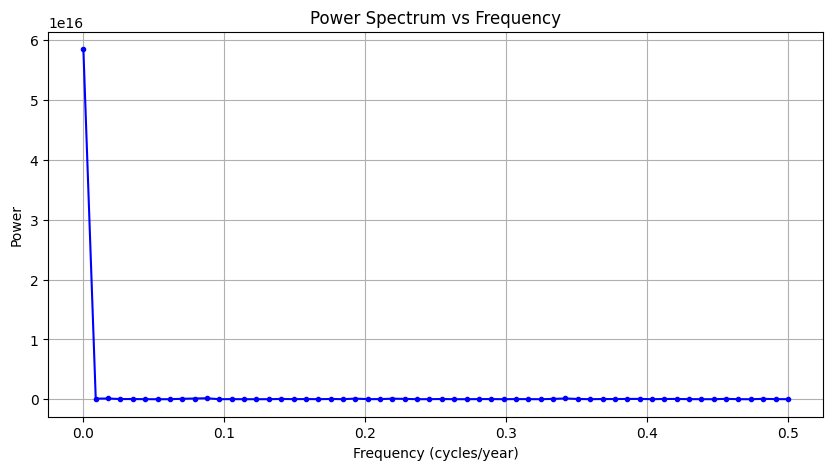


Top dominant frequencies:
Rank 1: Frequency = 0.0877 cycles/year (Period = 11.40 years), Power = 162968629781352.8125
Rank 2: Frequency = 0.3421 cycles/year (Period = 2.92 years), Power = 128342775850441.7344
Rank 3: Frequency = 0.0175 cycles/year (Period = 57.00 years), Power = 122497543319534.2188


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

file_path = 'assignment6.csv'
df = pd.read_csv(file_path)

if 'Flow' in df.columns:
    flow_data = df['Flow'].values
else:
    flow_data = df.iloc[:, 1].values

T = len(flow_data)

X_k = np.zeros(T, dtype=complex)

for k in range(T):
    sum_val = 0 + 0j
    for t in range(T):
        angle = -2 * np.pi * k * t / T
        sum_val += flow_data[t] * (np.cos(angle) + 1j * np.sin(angle))
    X_k[k] = sum_val

frequencies = np.arange(T) / T
power = np.abs(X_k) ** 2

half_T = T // 2
freq_half = frequencies[:half_T + 1]
power_half = power[:half_T + 1]

plt.figure(figsize=(10, 5))
plt.plot(freq_half, power_half, color='b', marker='o', linestyle='-', markersize=3)
plt.title('Power Spectrum vs Frequency')
plt.xlabel('Frequency (cycles/year)')
plt.ylabel('Power')
plt.grid(True)
plt.show()

sorted_indices = np.argsort(power_half)[::-1]

print("\nTop dominant frequencies:")
count = 0
for idx in sorted_indices:
    if freq_half[idx] == 0:
        continue
    print(f"Rank {count+1}: Frequency = {freq_half[idx]:.4f} cycles/year (Period = {1/freq_half[idx]:.2f} years), Power = {power_half[idx]:.4f}")
    count += 1
    if count == 3:
        break